<center><h1>Vo_Kevin_HW4</h1></center>
<br>
<br>

Name: Kevin Vo
<br>
Github Username: kb-vo
<br>
USC ID: 5124764281

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [92]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import warnings

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.feature_selection import RFECV, RFE
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
from scipy.special import logit
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import cross_val_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB

Get the AReM Data Set

In [93]:
DATA_DIR = "../data/AReM"
ACTIVITIES = {"bending1": 7, "bending2": 6, "cycling": 15, "lying": 15, "sitting": 15, "standing": 15, "walking": 15}
COLUMNS = ["time", "avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]
arem = pd.concat({(activity, i): pd.read_csv(f"{DATA_DIR}/{activity}/dataset{i}.csv", comment="#", names=COLUMNS, usecols=COLUMNS[1:], sep=r"[,\s]+", engine="python") for activity, n in ACTIVITIES.items() for i in range(1, n + 1)}, names=["activity", "dataset"])

### (b) Splitting Data

In [94]:
activity = arem.index.get_level_values("activity")
is_bending = activity.str.startswith("bending")
dataset = arem.index.get_level_values("dataset")
is_test = (is_bending & (dataset <= 2)) | (~is_bending & (dataset <= 3))
test, train = arem[is_test], arem[~is_test]

### (c) Feature Extraction

In [95]:
features = arem.groupby(["activity", "dataset"]).agg(["min", "max", "mean", "median", "std", lambda x: x.quantile(0.25), lambda x: x.quantile(0.75)])
features.columns = [f"{stat}_{i}" for i in range(1, 7) for stat in ["min", "max", "mean", "median", "std", "q1", "q3"]]
test_mask = features.index.isin(test.index.droplevel(-1))
X_train, X_test = features[~test_mask], features[test_mask]
y_train, y_test = X_train.index.get_level_values("activity").str.startswith("bending").astype(int), X_test.index.get_level_values("activity").str.startswith("bending").astype(int)
features

min_1  max_1     mean_1  median_1     std_1   q1_1     q3_1  \
activity dataset                                                                
bending1 1        37.25  45.00  40.624792     40.50  1.476967  39.25  42.0000   
         2        38.00  45.67  42.812812     42.50  1.435550  42.00  43.6700   
         3        35.00  47.40  43.954500     44.33  1.558835  43.00  45.0000   
         4        33.00  47.75  42.179813     43.50  3.670666  39.15  45.0000   
         5        33.00  45.75  41.678063     41.75  2.243490  41.33  42.7500   
...                 ...    ...        ...       ...       ...    ...      ...   
walking  11       19.50  45.33  33.586875     34.25  4.650935  30.25  37.0000   
         12       19.75  45.50  34.322750     35.25  4.752477  31.00  38.0000   
         13       19.50  46.00  34.546229     35.25  4.842294  31.25  37.8125   
         14       23.50  46.25  34.873229     35.25  4.531720  31.75  38.2500   
         15       19.25  44.00  34.473188     35.00  4.796705  31.25  38.0000   

                  min_2  max_2    mean_2  ...     std_5     q1_5   q3_5  \
activity dataset                          ...                             
bending1 1          0.0   1.30  0.358604  ...  2.188449  33.0000  36.00   
         2          0.0   1.22  0.372438  ...  1.995255  32.0000  34.50   
         3          0.0   1.70  0.426250  ...  1.999604  35.3625  36.50   
         4          0.0   3.00  0.696042  ...  3.849448  30.4575  36.33   
         5          0.0   2.83  0.535979  ...  2.411026  28.4575  31.25   
...                 ...    ...       ...  ...       ...      ...    ...   
walking  11         0.0  14.67  4.576562  ...  3.283983  13.7300  18.25   
         12         0.0  13.47  4.456333  ...  3.119856  13.5000  17.75   
         13         0.0  12.47  4.371958  ...  2.823124  14.0000  17.75   
         14         0.0  14.82  4.380583  ...  3.131076  13.7500  18.00   
         15         0.0  13.86  4.359312  ...  3.156320  13.7300  17.75   

                  min_6  max_6    mean_6  median_6     std_6    q1_6    q3_6  
activity dataset                                                              
bending1 1         0.00   1.92  0.570583      0.43  0.582915  0.0000  1.3000  
         2         0.00   3.11  0.571083      0.43  0.601010  0.0000  1.3000  
         3         0.00   1.79  0.493292      0.43  0.513506  0.0000  0.9400  
         4         0.00   2.18  0.613521      0.50  0.524317  0.0000  1.0000  
         5         0.00   1.79  0.383292      0.43  0.389164  0.0000  0.5000  
...                 ...    ...       ...       ...       ...     ...     ...  
walking  11        0.00   8.32  3.259729      3.11  1.640243  2.0500  4.3225  
         12        0.00   9.67  3.432563      3.20  1.732727  2.1575  4.5650  
         13        0.00  10.00  3.338125      3.08  1.656742  2.1600  4.3350  
         14        0.00   9.51  3.424646      3.27  1.690960  2.1700  4.5000  
         15        0.43   9.00  3.340458      3.09  1.699114  2.1200  4.3750  

[88 rows x 42 columns]

## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

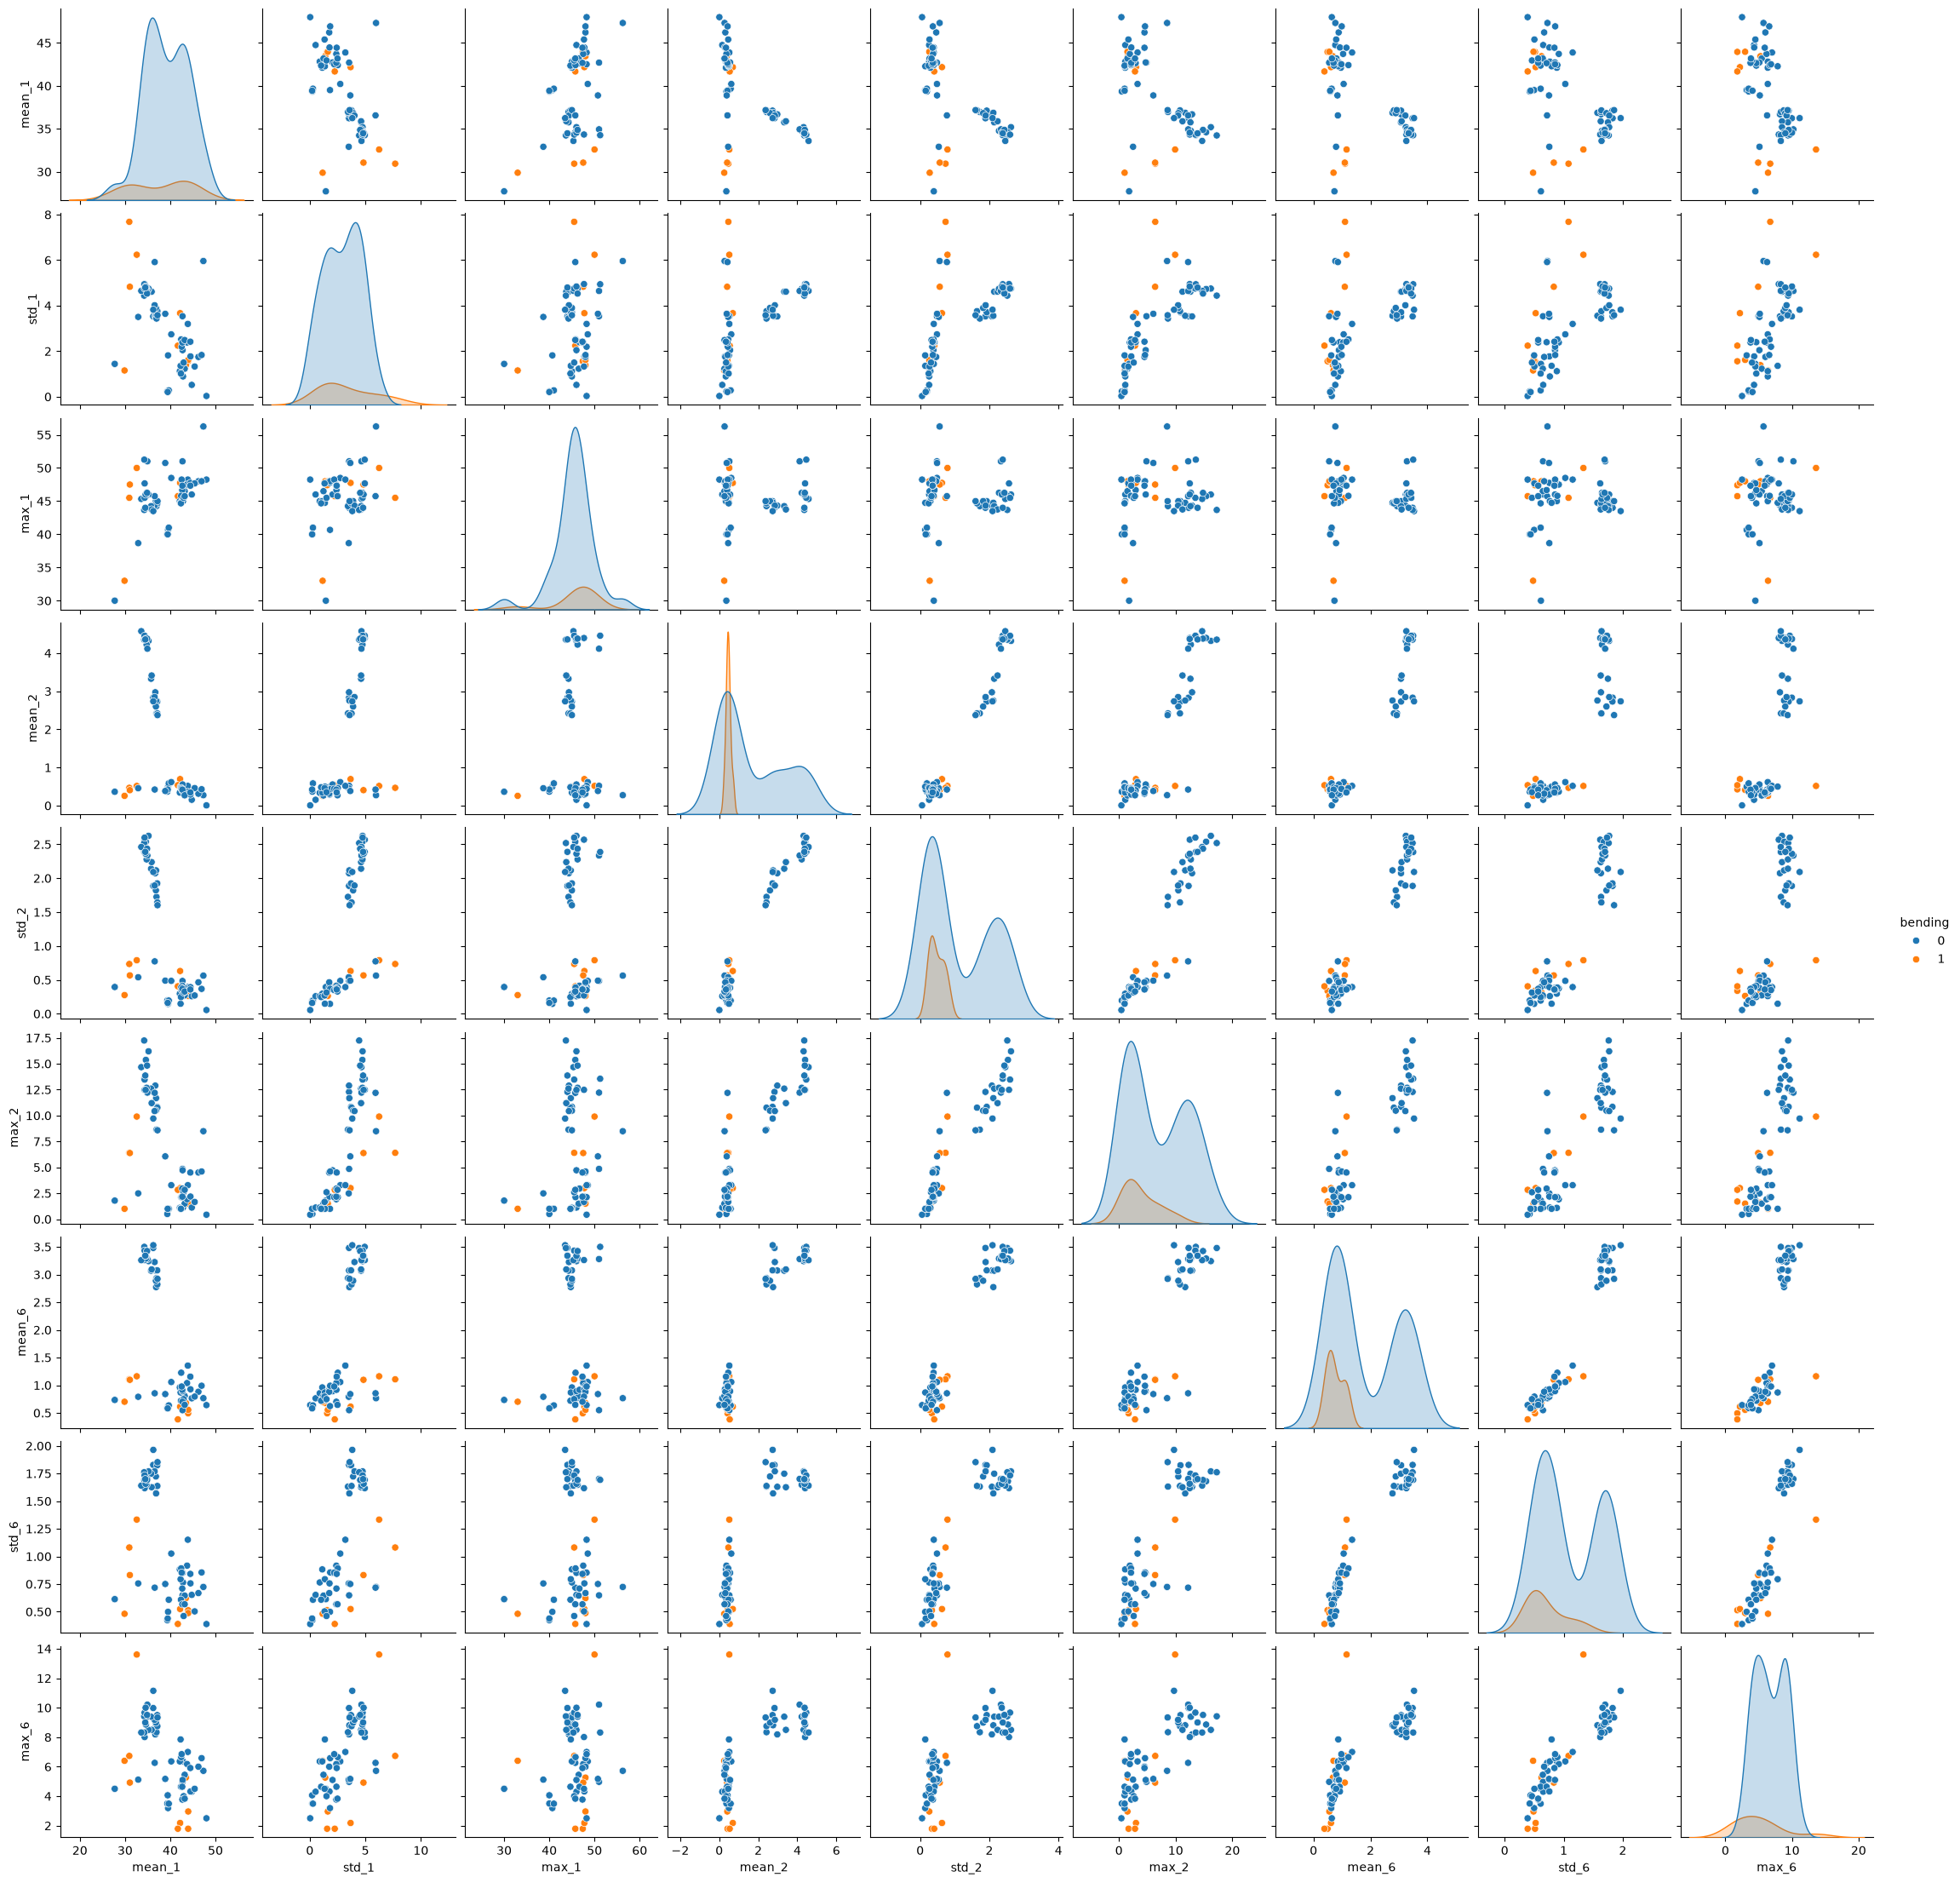

In [96]:
cols = [f"{stat}_{i}" for i in [1, 2, 6] for stat in ["mean", "std", "max"]]
sns.pairplot(X_train[cols].assign(bending=y_train), vars=cols, hue="bending")
plt.show()

#### ii. Splitted Plots

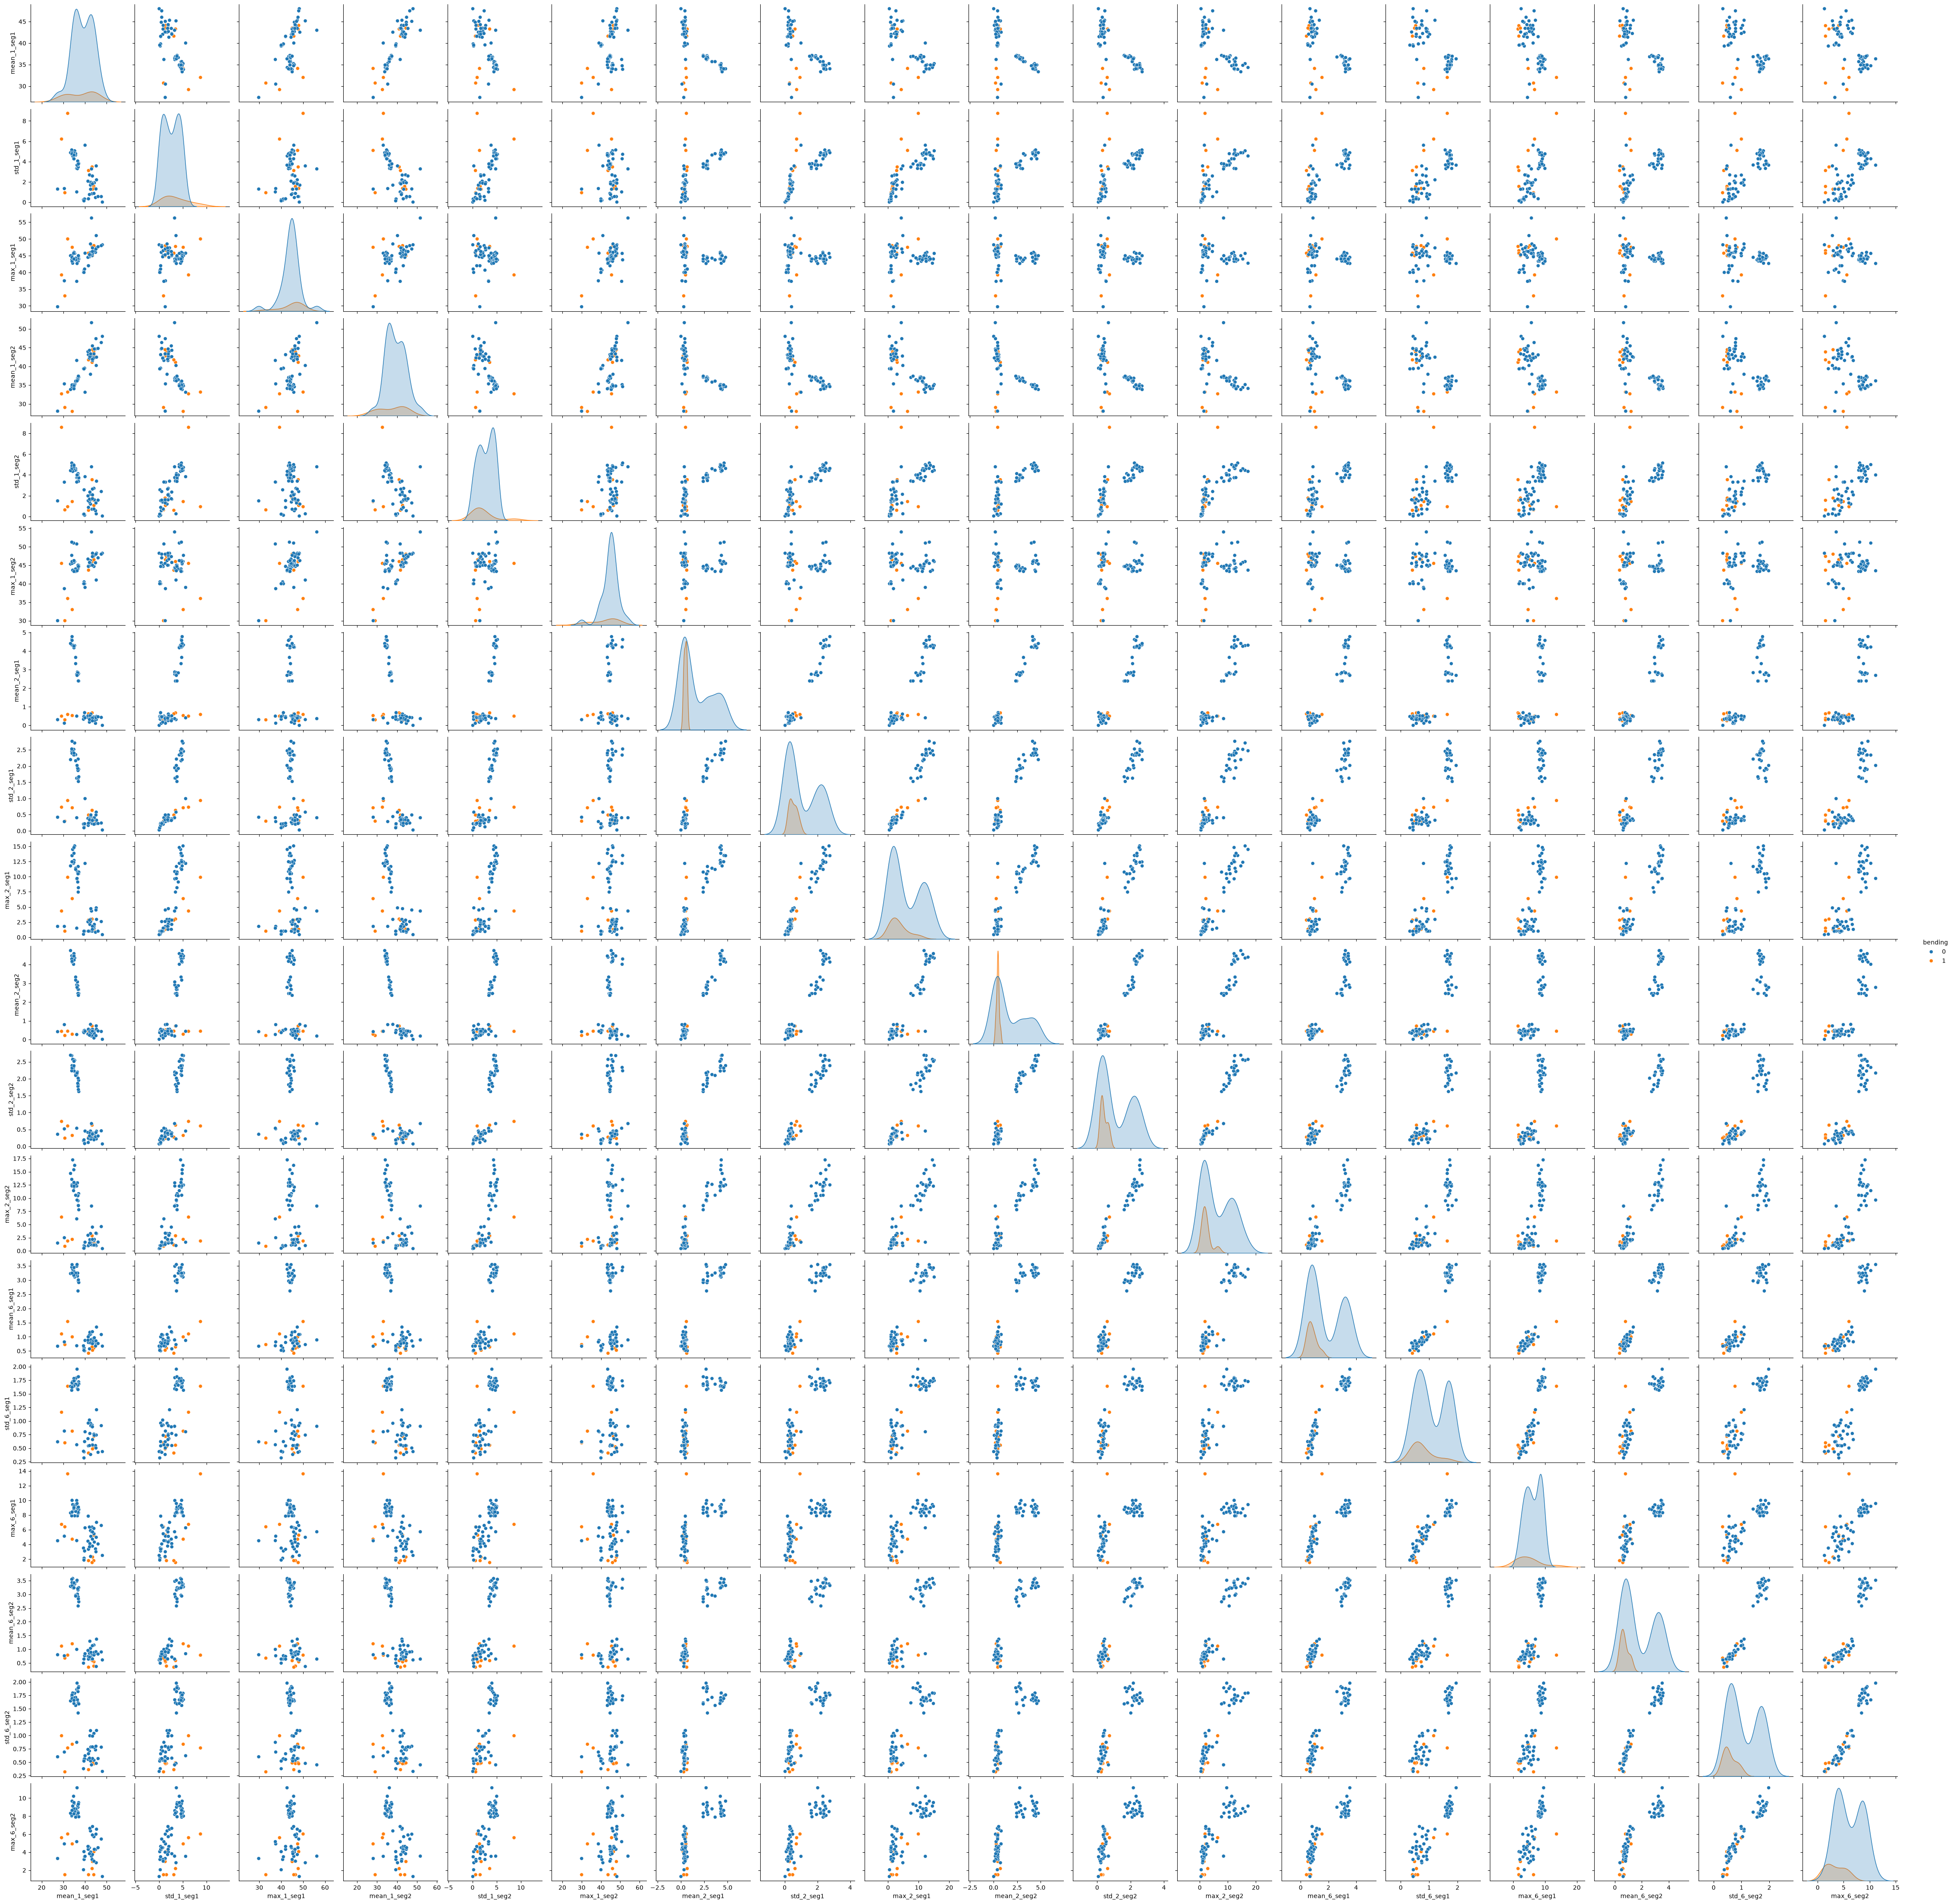

In [97]:
grouped = train.groupby(["activity", "dataset"])
segment = (grouped.cumcount() * 2 // grouped["avg_rss12"].transform("size")).rename("segment")
X_train2 = train.groupby(["activity", "dataset", segment]).agg(["min", "max", "mean", "median", "std", lambda x: x.quantile(0.25), lambda x: x.quantile(0.75)])
X_train2.columns = [f"{stat}_{i}" for i in range(1, 7) for stat in ["min", "max", "mean", "median", "std", "q1", "q3"]]
X_train2 = X_train2.unstack("segment")
X_train2.columns = [f"{name}_seg{s + 1}" for name, s in X_train2.columns]

cols = [f"{stat}_{i}_seg{s}" for i in [1, 2, 6] for s in [1, 2] for stat in ["mean", "std", "max"]]
sns.pairplot(X_train2[cols].assign(bending=y_train), vars=cols, hue="bending")
plt.show()

There is no considerable difference in the results with those from 2(a)i. Both halves show the same patterns as the full time series, with bending clustered at low values for time series 2 and 6 and overlapping with other activities for time series 1.

#### iii. Time Series Segments

In [98]:
model = make_pipeline(StandardScaler(), LogisticRegression(C=np.inf))
res = []

for l in range(1, 21):
    segment = (grouped.cumcount() * l // grouped["avg_rss12"].transform("size")).rename("segment")
    X_train_l = train.groupby(["activity", "dataset", segment]).agg(["min", "max", "mean", "median", "std", lambda x: x.quantile(0.25), lambda x: x.quantile(0.75)])
    X_train_l.columns = [f"{stat}_{i}" for i in range(1, 7) for stat in ["min", "max", "mean", "median", "std", "q1", "q3"]]
    X_train_l = X_train_l.unstack("segment")
    X_train_l.columns = [f"{name}_seg{s + 1}" for name, s in X_train_l.columns]

    rfecv = RFECV(model, cv=5, importance_getter="named_steps.logisticregression.coef_", n_jobs=-1).fit(X_train_l, y_train)
    res.append({"l": l, "p": rfecv.n_features_, "cv_accuracy": rfecv.cv_results_["mean_test_score"].max()})

res = pd.DataFrame(res).set_index("l")
best_l = res["cv_accuracy"].idxmax()
best_p = res.loc[best_l, "p"]
print(f"best l = {best_l}, best p = {best_p}")
res

best l = 3, best p = 1


,p,cv_accuracy
l,,
1,18,0.957143
2,2,0.957143
3,1,0.985714
4,23,0.971429
5,3,0.941758
6,5,0.971429
7,1,0.941758
8,3,0.941758
9,1,0.956044


The wrong way to perform cross-validation in this problem is to select features on the whole training set and then cross-validate, because the validation folds were already used to pick the features, so the CV accuracy would be higher than it should be. The right way is to select features inside each fold using only that fold’s training data, which RFECV does.

#### iv. Confusion Matrix

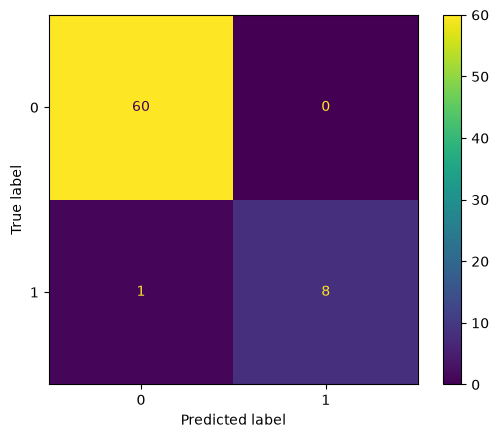

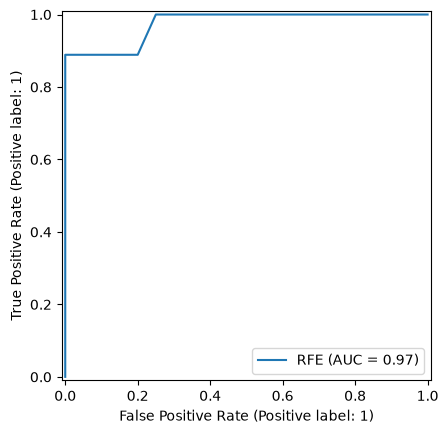

,Coef.,P>|z|
const,-21.851559,0.002844
max_5_seg1,0.765230,0.005198


In [99]:
segment = (grouped.cumcount() * best_l // grouped["avg_rss12"].transform("size")).rename("segment")
X_train_best = train.groupby(["activity", "dataset", segment]).agg(["min", "max", "mean", "median", "std", lambda x: x.quantile(0.25), lambda x: x.quantile(0.75)])
X_train_best.columns = [f"{stat}_{i}" for i in range(1, 7) for stat in ["min", "max", "mean", "median", "std", "q1", "q3"]]
X_train_best = X_train_best.unstack("segment")
X_train_best.columns = [f"{name}_seg{s + 1}" for name, s in X_train_best.columns]

rfe = RFE(model, n_features_to_select=best_p, importance_getter="named_steps.logisticregression.coef_").fit(X_train_best, y_train)
selected = X_train_best.columns[rfe.support_]

ConfusionMatrixDisplay.from_estimator(rfe, X_train_best, y_train)
RocCurveDisplay.from_estimator(rfe, X_train_best, y_train)
plt.show()

logit_res = sm.Logit(y_train, sm.add_constant(X_train_best[selected])).fit(disp=0)
logit_res.summary2().tables[1][["Coef.", "P>|z|"]]

#### v. Test Classifier

Test accuracy: 0.8947368421052632
CV accuracy: 0.9857142857142858


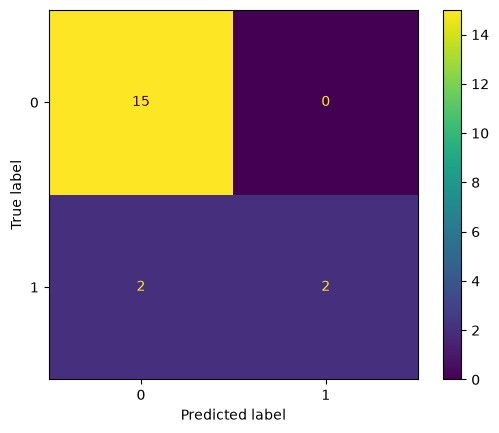

In [100]:
grouped_test = test.groupby(["activity", "dataset"])
segment_test = (grouped_test.cumcount() * best_l // grouped_test["avg_rss12"].transform("size")).rename("segment")
X_test_best = test.groupby(["activity", "dataset", segment_test]).agg(["min", "max", "mean", "median", "std", lambda x: x.quantile(0.25), lambda x: x.quantile(0.75)])
X_test_best.columns = [f"{stat}_{i}" for i in range(1, 7) for stat in ["min", "max", "mean", "median", "std", "q1", "q3"]]
X_test_best = X_test_best.unstack("segment")
X_test_best.columns = [f"{name}_seg{s + 1}" for name, s in X_test_best.columns]

print(f"Test accuracy: {rfe.score(X_test_best, y_test)}")
print(f"CV accuracy: {res.loc[best_l, 'cv_accuracy']}")
ConfusionMatrixDisplay.from_estimator(rfe, X_test_best, y_test)
plt.show()

The accuracy on the test set (0.8947368421052632) is lower than the cross-validation accuracy (0.9857142857142858).

#### vi. Separation

No, the classes don’t seem to be well-separated enough to cause instability in calculating the logistic regression parameters, because one bending instance is still misclassified on the training data.

#### vii. Imbalance

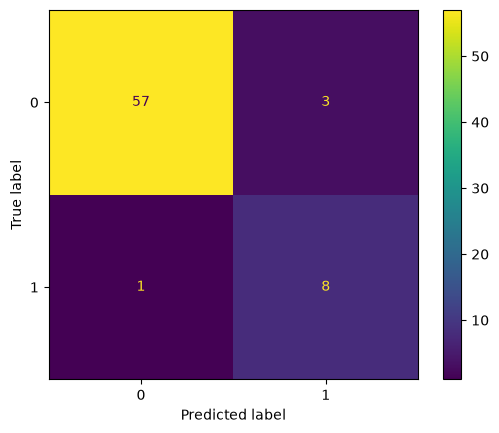

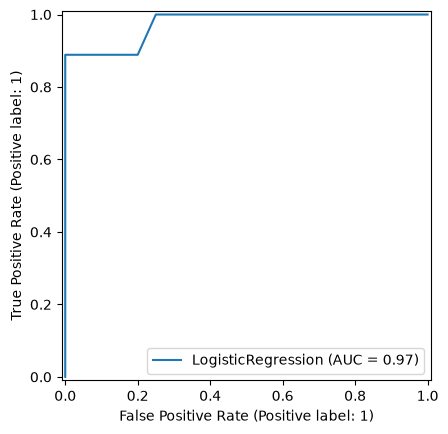

In [101]:
cases = X_train_best[y_train == 1]
controls = X_train_best[y_train == 0].sample(n=len(cases), random_state=42)
X_cc = pd.concat([cases, controls])[selected]
y_cc = X_cc.index.get_level_values("activity").str.startswith("bending").astype(int)

cc_model = LogisticRegression(C=np.inf).fit(X_cc, y_cc)
pi, pi_cc = y_train.mean(), y_cc.mean()
cc_model.intercept_ += logit(pi) - logit(pi_cc)

ConfusionMatrixDisplay.from_estimator(cc_model, X_train_best[selected], y_train)
RocCurveDisplay.from_estimator(cc_model, X_train_best[selected], y_train)
plt.show()

Yes, the classes are imbalanced, with 9 bending instances vs. 60 non-bending instances in the training set, and 4 bending vs. 15 non-bending instances in the test set.

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [102]:
model_l1 = make_pipeline(StandardScaler(), LogisticRegressionCV(l1_ratios=(1,), solver="liblinear", cv=5, scoring="accuracy", use_legacy_attributes=False, n_jobs=-1, random_state=42))
res_l1 = []

for l in range(1, 21):
    segment = (grouped.cumcount() * l // grouped["avg_rss12"].transform("size")).rename("segment")
    X_train_l = train.groupby(["activity", "dataset", segment]).agg(["min", "max", "mean", "median", "std", lambda x: x.quantile(0.25), lambda x: x.quantile(0.75)])
    X_train_l.columns = [f"{stat}_{i}" for i in range(1, 7) for stat in ["min", "max", "mean", "median", "std", "q1", "q3"]]
    X_train_l = X_train_l.unstack("segment")
    X_train_l.columns = [f"{name}_seg{s + 1}" for name, s in X_train_l.columns]

    lrcv = model_l1.fit(X_train_l, y_train)[-1]
    res_l1.append({"l": l, "C": lrcv.C_, "cv_accuracy": lrcv.scores_.mean(axis=0).max()})

res_l1 = pd.DataFrame(res_l1).set_index("l")
best_l1_l = res_l1["cv_accuracy"].idxmax()
best_C = res_l1.loc[best_l1_l, "C"]
print(f"Best l = {best_l1_l}, best C = {best_C}")
res_l1

Best l = 1, best C = 0.3593813663804626


,C,cv_accuracy
l,,
1,0.359381,0.971429
2,0.359381,0.957143
3,0.359381,0.971429
4,0.359381,0.957143
5,21.544347,0.942857
6,0.359381,0.957143
7,2.782559,0.956044
8,0.359381,0.941758
9,2.782559,0.957143


#### ii. Comparison

Variable selection using p-values performed better, with a CV accuracy of 0.9857142857142858 compared to 0.971429 for L1-penalized. L1-penalized is easier to implement, since feature selection happens automatically through the penalty and only C needs to be tuned.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

Best l = 1, best C = 2.782559402207126


,C,cv_accuracy
l,,
1,2.782559,0.913187
2,21.544347,0.913187
3,21.544347,0.840659
4,21.544347,0.870330
5,166.810054,0.853846
6,2.782559,0.826374
7,2.782559,0.826374
8,2.782559,0.782418
9,166.810054,0.784615


Test error: 0.10526315789473684


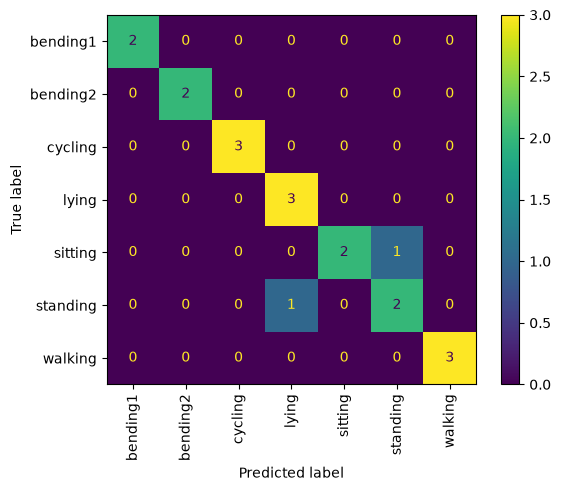

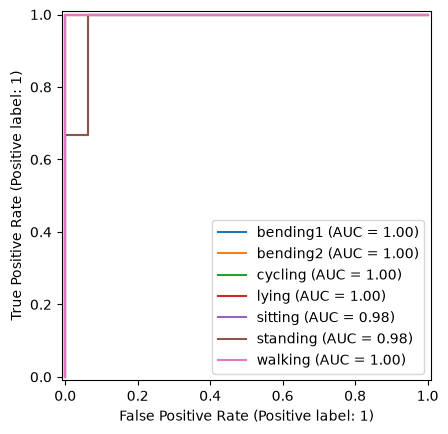

In [103]:
warnings.filterwarnings("ignore", message="The least populated class")
warnings.filterwarnings("ignore", category=ConvergenceWarning)

model_multi = make_pipeline(StandardScaler(), LogisticRegressionCV(l1_ratios=(1,), solver="saga", cv=5, scoring="accuracy", use_legacy_attributes=False, n_jobs=-1, random_state=42))
y_train_multi = X_train.index.get_level_values("activity")
y_test_multi = X_test.index.get_level_values("activity")
res_multi = []

for l in range(1, 21):
    segment = (grouped.cumcount() * l // grouped["avg_rss12"].transform("size")).rename("segment")
    X_train_l = train.groupby(["activity", "dataset", segment]).agg(["min", "max", "mean", "median", "std", lambda x: x.quantile(0.25), lambda x: x.quantile(0.75)])
    X_train_l.columns = [f"{stat}_{i}" for i in range(1, 7) for stat in ["min", "max", "mean", "median", "std", "q1", "q3"]]
    X_train_l = X_train_l.unstack("segment")
    X_train_l.columns = [f"{name}_seg{s + 1}" for name, s in X_train_l.columns]

    lrcv = model_multi.fit(X_train_l, y_train_multi)[-1]
    res_multi.append({"l": l, "C": lrcv.C_, "cv_accuracy": lrcv.scores_.mean(axis=0).max()})

res_multi = pd.DataFrame(res_multi).set_index("l")
best_multi_l = res_multi["cv_accuracy"].idxmax()
print(f"Best l = {best_multi_l}, best C = {res_multi.loc[best_multi_l, 'C']}")
display(res_multi)

grouped_all = arem.groupby(["activity", "dataset"])
segment_all = (grouped_all.cumcount() * best_multi_l // grouped_all["avg_rss12"].transform("size")).rename("segment")
X_multi = arem.groupby(["activity", "dataset", segment_all]).agg(["min", "max", "mean", "median", "std", lambda x: x.quantile(0.25), lambda x: x.quantile(0.75)])
X_multi.columns = [f"{stat}_{i}" for i in range(1, 7) for stat in ["min", "max", "mean", "median", "std", "q1", "q3"]]
X_multi = X_multi.unstack("segment")
X_multi.columns = [f"{name}_seg{s + 1}" for name, s in X_multi.columns]
X_train_multi, X_test_multi = X_multi[~test_mask], X_multi[test_mask]

model_multi.fit(X_train_multi, y_train_multi)
print(f"Test error: {1 - model_multi.score(X_test_multi, y_test_multi)}")

ConfusionMatrixDisplay.from_estimator(model_multi, X_test_multi, y_test_multi, xticks_rotation="vertical")
y_score = model_multi.predict_proba(X_test_multi)
fig, ax = plt.subplots()
for i, activity in enumerate(model_multi.classes_):
    RocCurveDisplay.from_predictions(y_test_multi == activity, y_score[:, i], name=activity, ax=ax)
plt.show()

#### ii. Naive Bayes

,gaussian_cv_accuracy,multinomial_cv_accuracy
l,,
1,0.813187,0.826374
2,0.813187,0.768132
3,0.667033,0.753846
4,0.637363,0.769231
5,0.606593,0.768132
6,0.624176,0.739560
7,0.623077,0.782418
8,0.638462,0.768132
9,0.581319,0.753846


gaussian: best l = 1, test error = 0.10526315789473684


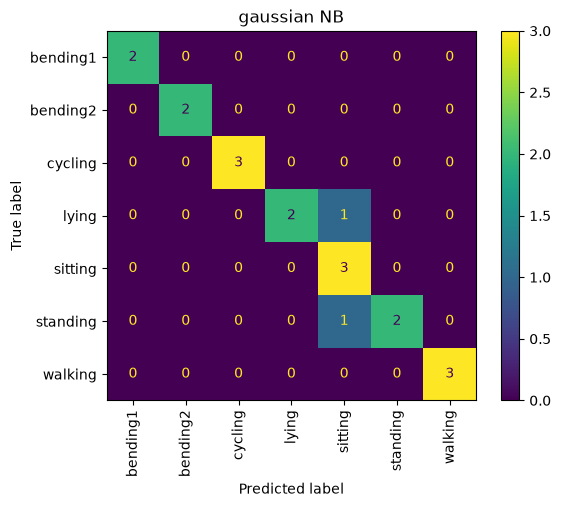

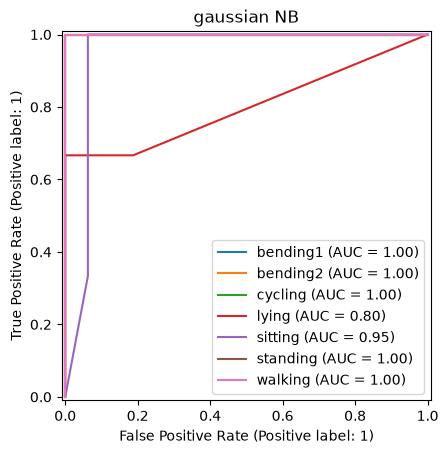

multinomial: best l = 1, test error = 0.10526315789473684


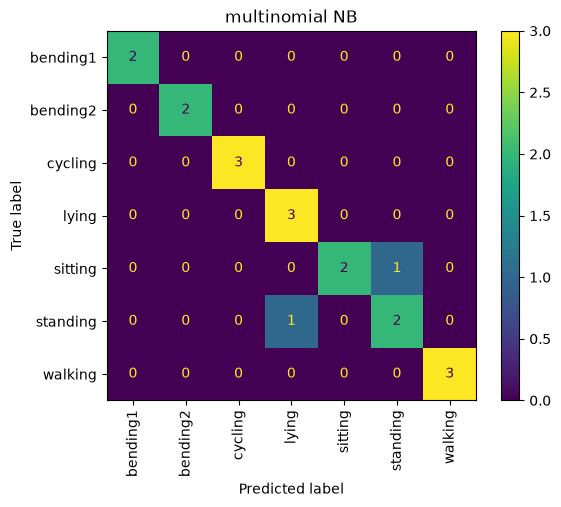

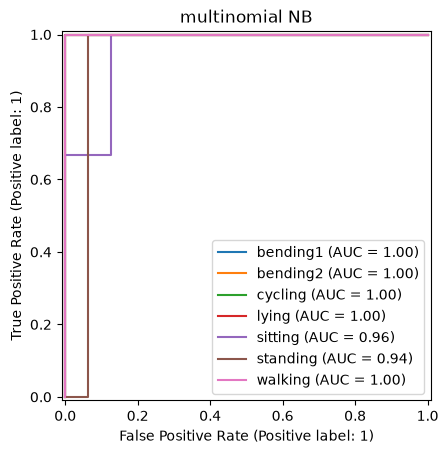

In [104]:
res_nb = []

for l in range(1, 21):
    segment = (grouped.cumcount() * l // grouped["avg_rss12"].transform("size")).rename("segment")
    X_train_l = train.groupby(["activity", "dataset", segment]).agg(["min", "max", "mean", "median", "std", lambda x: x.quantile(0.25), lambda x: x.quantile(0.75)])
    X_train_l.columns = [f"{stat}_{i}" for i in range(1, 7) for stat in ["min", "max", "mean", "median", "std", "q1", "q3"]]
    X_train_l = X_train_l.unstack("segment")
    X_train_l.columns = [f"{name}_seg{s + 1}" for name, s in X_train_l.columns]

    res_nb.append({"l": l, "gaussian_cv_accuracy": cross_val_score(GaussianNB(), X_train_l, y_train_multi, cv=5, n_jobs=-1).mean(), "multinomial_cv_accuracy": cross_val_score(MultinomialNB(), X_train_l, y_train_multi, cv=5, n_jobs=-1).mean()})

res_nb = pd.DataFrame(res_nb).set_index("l")
display(res_nb)

for prior, nb_model in [("gaussian", GaussianNB()), ("multinomial", MultinomialNB())]:
    best_nb_l = res_nb[f"{prior}_cv_accuracy"].idxmax()
    segment_all = (grouped_all.cumcount() * best_nb_l // grouped_all["avg_rss12"].transform("size")).rename("segment")
    X_nb = arem.groupby(["activity", "dataset", segment_all]).agg(["min", "max", "mean", "median", "std", lambda x: x.quantile(0.25), lambda x: x.quantile(0.75)])
    X_nb.columns = [f"{stat}_{i}" for i in range(1, 7) for stat in ["min", "max", "mean", "median", "std", "q1", "q3"]]
    X_nb = X_nb.unstack("segment")
    X_nb.columns = [f"{name}_seg{s + 1}" for name, s in X_nb.columns]
    X_train_nb, X_test_nb = X_nb[~test_mask], X_nb[test_mask]

    nb_model.fit(X_train_nb, y_train_multi)
    print(f"{prior}: best l = {best_nb_l}, test error = {1 - nb_model.score(X_test_nb, y_test_multi)}")

    ConfusionMatrixDisplay.from_estimator(nb_model, X_test_nb, y_test_multi, xticks_rotation="vertical").ax_.set_title(f"{prior} NB")
    y_score = nb_model.predict_proba(X_test_nb)
    fig, ax = plt.subplots()
    for i, activity in enumerate(nb_model.classes_):
        RocCurveDisplay.from_predictions(y_test_multi == activity, y_score[:, i], name=activity, ax=ax)
    ax.set_title(f"{prior} NB")
    plt.show()

#### iii. Comparison

L1-penalized multinomial logistic regression is better for multi-class classification in this problem. All three methods had the same test error of 0.10526315789473684, but L1-penalized multinomial logistic regression had the highest CV accuracy (0.913187), compared to 0.813187 for Gaussian Naive Bayes and 0.826374 for Multinomial Naive Bayes.

## 3. ISLR 4.8.3

By (4.15), the Bayes classifier assigns $x$ to the class with the largest $\pi_k f_k(x)$, since the denominator is the same for every class. Plugging in (4.16) without assuming $\sigma_1^2 = \dots = \sigma_K^2$ and taking the log:

$$\log(\pi_k f_k(x)) = \log(\pi_k) - \log(\sqrt{2\pi}) - \log(\sigma_k) - \frac{(x - \mu_k)^2}{2\sigma_k^2}$$

Dropping $-\log(\sqrt{2\pi})$, which is the same for every class, and expanding $(x - \mu_k)^2$:

$$\delta_k(x) = -\frac{x^2}{2\sigma_k^2} + \frac{x \mu_k}{\sigma_k^2} - \frac{\mu_k^2}{2\sigma_k^2} - \log(\sigma_k) + \log(\pi_k)$$

In (4.18), all classes share $\sigma^2$, so the $x^2$ term is the same for every class and drops out, leaving a linear function of $x$. Here the $\sigma_k^2$ differ, so the $x^2$ term does not drop out, which makes $\delta_k(x)$ quadratic in $x$ and the Bayes classifier not linear.

## 4. ISLR 4.8.7

Bayes' theorem is applied with the normal density function, where $\pi_{Yes} = 0.8$, $\pi_{No} = 0.2$, $\mu_{Yes} = 10$, $\mu_{No} = 0$, and $\sigma^2 = 36$. The $\frac{1}{\sqrt{2\pi\sigma^2}}$ factor cancels since both classes share the same variance:

$$P(Yes \mid X = 4) = \frac{0.8 \cdot e^{-(4-10)^2/(2 \cdot 36)}}{0.8 \cdot e^{-(4-10)^2/(2 \cdot 36)} + 0.2 \cdot e^{-(4-0)^2/(2 \cdot 36)}}$$

$$= \frac{0.8 \cdot e^{-0.5}}{0.8 \cdot e^{-0.5} + 0.2 \cdot e^{-0.2222}}$$

$$= \frac{0.8 \cdot 0.6065}{0.8 \cdot 0.6065 + 0.2 \cdot 0.8007}$$

$$= \frac{0.4852}{0.4852 + 0.1601} \approx 0.752$$

The probability that the company issues a dividend is about 75.2%.

## 5.1. Extra Practice ISLR 4.8.4

## 5.2. Extra Practice ISLR 4.8.9